In [68]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [69]:
df=pd.read_csv("/content/AB_NYC_2019.csv")

In [70]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [71]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [72]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [73]:
df.isnull().mean() * 100

,0
id,0.000000
name,0.032723
host_id,0.000000
host_name,0.042949
neighbourhood_group,0.000000
neighbourhood,0.000000
latitude,0.000000
longitude,0.000000
room_type,0.000000
price,0.000000


In [74]:
df.loc[df["reviews_per_month"].isnull(),"number_of_reviews"].value_counts()

,count
number_of_reviews,
0,10052


In [75]:
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

In [76]:
df["reviews_per_month"].isnull().sum()

np.int64(0)

In [77]:
df = df.drop(columns=["name", "host_id", "id", "host_name", "last_review", "neighbourhood"])

In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 10 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             48895 non-null  object 
 1   latitude                        48895 non-null  float64
 2   longitude                       48895 non-null  float64
 3   room_type                       48895 non-null  object 
 4   price                           48895 non-null  int64  
 5   minimum_nights                  48895 non-null  int64  
 6   number_of_reviews               48895 non-null  int64  
 7   reviews_per_month               48895 non-null  float64
 8   calculated_host_listings_count  48895 non-null  int64  
 9   availability_365                48895 non-null  int64  
dtypes: float64(3), int64(5), object(2)
memory usage: 3.7+ MB


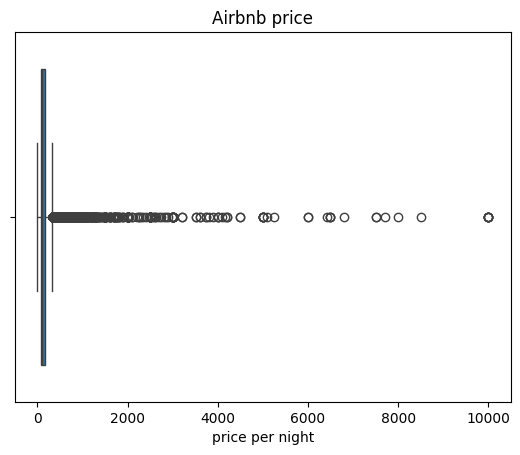

Text(0.5, 0, 'minimum nights')

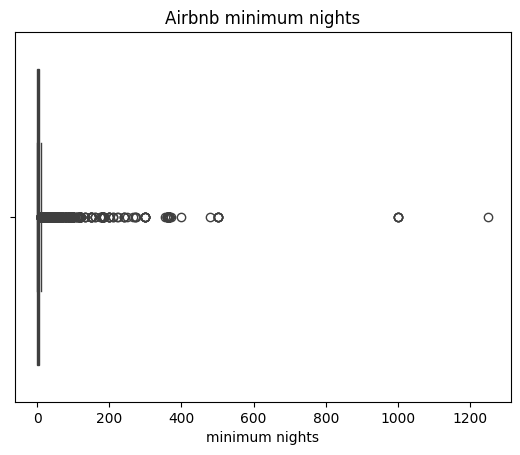

In [79]:
sns.boxplot(x=df["price"])
plt.title("Airbnb price")
plt.xlabel("price per night")
plt.show()
sns.boxplot(x=df["minimum_nights"])
plt.title("Airbnb minimum nights")
plt.xlabel("minimum nights")

In [80]:
price_limit = df["price"].quantile(0.95)
nights_limit = df["minimum_nights"].quantile(0.95)
print("Price Limit:", price_limit)
print("Nights Limit:", nights_limit)


Price Limit: 355.0
Nights Limit: 30.0


In [81]:
print("Rows before:", len(df))
df = df[(df["price"] > 0) & (df["price"] <= price_limit) & (df["minimum_nights"] <= nights_limit)].copy()
print("Rows after:", len(df))

Rows before: 48895
Rows after: 45748


In [82]:
df = pd.get_dummies(df, columns=["room_type", "neighbourhood_group"], drop_first=True, dtype=int)

In [83]:
X = df.drop(columns=["price"])
y = df["price"]

In [84]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42)
print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))

Training Rows: 36598
Testing Rows: 9150


In [85]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [86]:
y_pred = model.predict(X_test)
comparison = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
comparison.head(10)

,Actual,Predicted
4948,80,107.114432
1629,73,145.833190
22548,186,184.774299
7886,150,166.007019
11047,229,140.962172
3941,180,157.897992
43706,180,145.200040
12574,49,72.325283
424,145,142.100589
15258,54,90.995701


In [87]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
print("R2 Score:", round(r2, 3))
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))

R2 Score: 0.487
MAE: 38.32
MSE: 2760.62
RMSE: 52.54


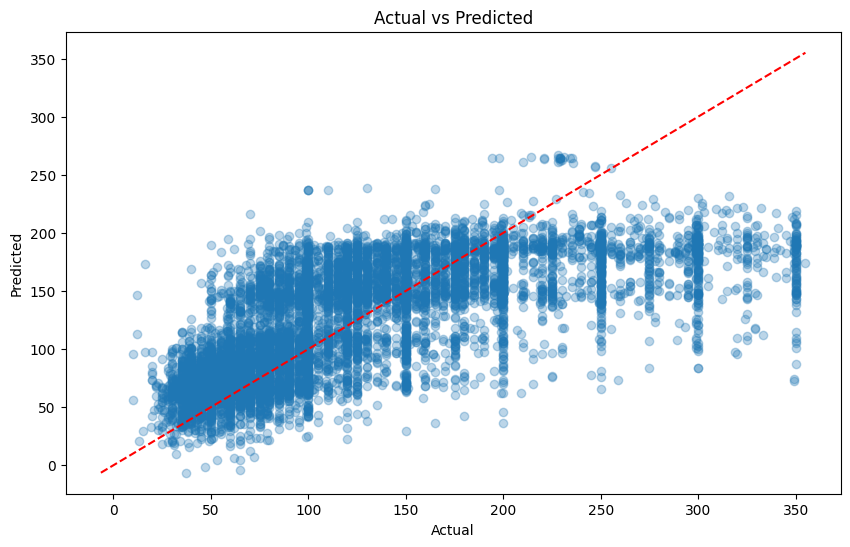

In [88]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
low = min(min(y_test), min(y_pred))
high = max(max(y_test), max(y_pred))
plt.plot([low, high], [low, high], 'r--')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.show()

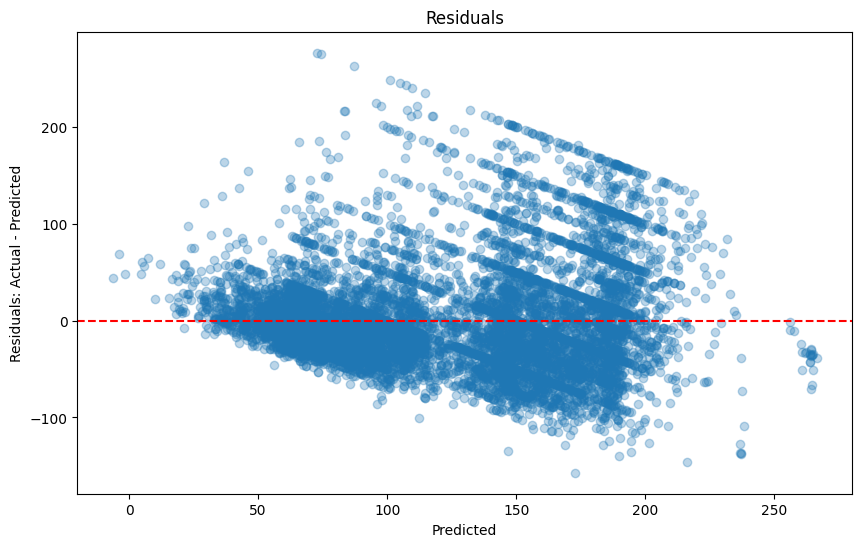

In [89]:
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted")
plt.ylabel("Residuals: Actual - Predicted")
plt.title("Residuals")
plt.show()